In [1]:
!git clone -q https://github.com/rachandeepkaur/battery-soh-prediction.git
%cd battery-soh-prediction

import sys, warnings
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from src import evaluation as ev

df = ev.load_labelled()
numeric, categorical = ev.main_features()
print(df.shape, len(numeric), categorical)

/content/battery-soh-prediction
(306, 76) 42 ['schedule']


In [2]:
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel as C, RBF, Matern, WhiteKernel

# Ridge = the reference to beat
ridge = ev.ModelSpec("Ridge", Ridge(), {"alpha": np.logspace(-2, 3, 11)}, family="linear")

# SVR with RBF kernel: tune C, gamma, epsilon
svr = ev.ModelSpec(
    "SVR (RBF)", SVR(kernel="rbf"),
    {"C": [1, 10, 30, 100, 300],
     "gamma": ["scale", 0.003, 0.01, 0.03, 0.1],
     "epsilon": [0.1, 0.5, 1.0]},
    family="non-linear")

# Gaussian Process: the grid only picks the kernel type
def k_rbf():  return C(1.0, (1e-2, 1e3)) * RBF(5.0, (1e-2, 1e3)) + WhiteKernel(1.0, (1e-5, 1e2))
def k_m15():  return C(1.0, (1e-2, 1e3)) * Matern(5.0, (1e-2, 1e3), nu=1.5) + WhiteKernel(1.0, (1e-5, 1e2))
def k_m25():  return C(1.0, (1e-2, 1e3)) * Matern(5.0, (1e-2, 1e3), nu=2.5) + WhiteKernel(1.0, (1e-5, 1e2))

gpr = ev.ModelSpec(
    "Gaussian process",
    GaussianProcessRegressor(normalize_y=True, n_restarts_optimizer=2, random_state=0),
    {"kernel": [k_rbf(), k_m15(), k_m25()]},
    family="non-linear")

print("Models ready:", ridge.name, "|", svr.name, "|", gpr.name)

Models ready: Ridge | SVR (RBF) | Gaussian process


In [3]:
%%time
results = []
for spec in [ridge, svr, gpr]:
    results.append(ev.run_cv(df, spec, "LOCO"))

R = {(r.model, r.scheme): r for r in results}
display(ev.summary_table(results).round(2))

Ridge | LOCO: fold 15
SVR (RBF) | LOCO: fold 15
Gaussian process | LOCO: fold 15


,model,scheme,n,MAE,RMSE,R2,MaxAE
0,Ridge,LOCO,306,5.02,8.13,0.46,53.21
1,SVR (RBF),LOCO,306,4.58,7.69,0.52,54.76
2,Gaussian process,LOCO,306,7.37,12.38,-0.24,56.06


CPU times: user 1min 7s, sys: 3.68 s, total: 1min 10s
Wall time: 28min 12s


In [4]:
models = ["Ridge", "SVR (RBF)", "Gaussian process"]

# 1) MAE for each held-out cell, models side by side
folds = pd.concat([R[(m, "LOCO")].folds for m in models])
display(folds.pivot(index="held_out", columns="model", values="MAE")[models].round(2))

# 2) Settings each fold picked
for m in ["SVR (RBF)", "Gaussian process"]:
    print("\n", m)
    display(R[(m, "LOCO")].folds[["held_out", "best_params"]])

# 3) The 10 worst predictions (where MaxAE ~55 comes from)
oof = pd.concat([R[(m, "LOCO")].oof for m in models])
oof["abs_err"] = (oof.y_pred - oof.y_true).abs()
display(oof.sort_values("abs_err", ascending=False)
           [["model", "cell_id", "rtp_index", "y_true", "y_pred", "abs_err", "regime"]].head(10).round(2))

model,Ridge,SVR (RBF),Gaussian process
held_out,,,
2_009,1.90,1.79,1.39
2_010,2.71,2.26,2.42
2_012,10.76,7.86,11.41
2_027,2.33,2.68,2.37
2_030,4.78,6.18,11.77
2_033,6.30,6.51,2.97
2_058,2.14,2.15,1.99
2_067,6.18,6.46,8.36
2_076,13.92,16.17,18.51



 SVR (RBF)


,held_out,best_params
0,2_009,"{'C': 30, 'epsilon': 0.5, 'gamma': 0.003}"
1,2_010,"{'C': 30, 'epsilon': 0.1, 'gamma': 0.003}"
2,2_012,"{'C': 100, 'epsilon': 0.1, 'gamma': 0.003}"
3,2_027,"{'C': 30, 'epsilon': 0.5, 'gamma': 0.003}"
4,2_030,"{'C': 300, 'epsilon': 0.5, 'gamma': 0.003}"
5,2_033,"{'C': 100, 'epsilon': 1.0, 'gamma': 0.003}"
6,2_058,"{'C': 100, 'epsilon': 0.1, 'gamma': 0.003}"
7,2_067,"{'C': 10, 'epsilon': 1.0, 'gamma': 0.003}"
8,2_076,"{'C': 10, 'epsilon': 1.0, 'gamma': 0.01}"
9,2_092,"{'C': 30, 'epsilon': 0.5, 'gamma': 0.003}"



 Gaussian process


,held_out,best_params
0,2_009,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
1,2_010,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
2,2_012,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
3,2_027,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
4,2_030,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
5,2_033,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
6,2_058,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
7,2_067,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
8,2_076,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."
9,2_092,"{'kernel': 1**2 * Matern(length_scale=5, nu=1...."


,model,cell_id,rtp_index,y_true,y_pred,abs_err,regime
215,Gaussian process,2_095,15,33.26,89.32,56.06,extrapolation
215,SVR (RBF),2_095,15,33.26,88.02,54.76,extrapolation
215,Ridge,2_095,15,33.26,86.47,53.21,extrapolation
216,Gaussian process,2_095,16,38.40,89.04,50.64,extrapolation
216,SVR (RBF),2_095,16,38.40,87.88,49.47,extrapolation
216,Ridge,2_095,16,38.40,86.30,47.89,extrapolation
199,Gaussian process,2_092,21,89.95,42.56,47.40,extrapolation
200,Gaussian process,2_092,22,88.20,40.91,47.30,extrapolation
198,Gaussian process,2_092,20,90.32,44.73,45.59,extrapolation
197,Gaussian process,2_092,19,90.58,46.55,44.03,extrapolation


In [5]:
# 1) Paired comparison on the same 15 folds (negative mean_diff = model "a" is better)
display(pd.DataFrame([
    ev.paired_comparison(R[("SVR (RBF)", "LOCO")],        R[("Ridge", "LOCO")]),
    ev.paired_comparison(R[("Gaussian process", "LOCO")], R[("Ridge", "LOCO")]),
    ev.paired_comparison(R[("Gaussian process", "LOCO")], R[("SVR (RBF)", "LOCO")]),
]).round(3))

# 2) Error by health class and by interpolation vs extrapolation
for m in models:
    oof_m = R[(m, "LOCO")].oof
    print(f"\n===== {m} =====")
    display(ev.breakdown(oof_m, "health_class").round(2))
    display(ev.breakdown(oof_m, "regime").round(2))

,a,b,scheme,n_folds,mean_diff,a_wins,b_wins,wilcoxon_p
0,SVR (RBF),Ridge,LOCO,15,-0.303,7,8,0.978
1,Gaussian process,Ridge,LOCO,15,2.434,5,10,0.048
2,Gaussian process,SVR (RBF),LOCO,15,2.737,5,10,0.041



===== Ridge =====


,health_class,n,MAE,RMSE,bias
0,EOL risk (<80),53,12.59,16.70,12.00
1,Degraded (80-90),66,3.36,4.44,-1.53
2,Healthy (>=90),187,3.46,4.71,-1.99


,regime,n,MAE,RMSE,bias
0,extrapolation,66,11.61,14.97,3.83
1,interpolation,219,2.92,3.66,-0.93
2,unclassified,21,6.18,10.91,5.43



===== SVR (RBF) =====


,health_class,n,MAE,RMSE,bias
0,EOL risk (<80),53,12.03,16.53,11.21
1,Degraded (80-90),66,3.43,4.07,-0.81
2,Healthy (>=90),187,2.87,3.67,-1.48


,regime,n,MAE,RMSE,bias
0,extrapolation,66,9.08,13.62,5.29
1,interpolation,219,3.04,3.85,-0.99
2,unclassified,21,6.46,11.16,6.24



===== Gaussian process =====


,health_class,n,MAE,RMSE,bias
0,EOL risk (<80),53,14.83,18.38,14.15
1,Degraded (80-90),66,6.12,10.10,-0.83
2,Healthy (>=90),187,5.70,10.91,-3.99


,regime,n,MAE,RMSE,bias
0,extrapolation,66,19.25,24.03,-1.21
1,interpolation,219,3.70,5.09,-0.67
2,unclassified,21,8.36,12.19,8.32


In [6]:
%%time
gp_res = R[("Gaussian process", "LOCO")]
X = df[numeric + categorical + ["cell_id"]]
y = df["SOH"].to_numpy(float)
mu, sd = np.zeros(len(df)), np.zeros(len(df))

for k, (tr, te) in enumerate(ev.outer_folds(df, "LOCO")):
    kern = gp_res.folds.loc[k, "best_params"]["kernel"]
    pipe = ev.make_pipeline(clone(gpr.estimator).set_params(kernel=kern), numeric, categorical)
    pipe.fit(X.iloc[tr], y[tr])
    Z = pipe.named_steps["prep"].transform(X.iloc[te])
    mu[te], sd[te] = pipe.named_steps["model"].predict(Z, return_std=True)

print("MAE check (should be 7.37):", np.abs(mu - y).mean().round(2))

lo, hi = mu - 1.96 * sd, mu + 1.96 * sd
unc = df[["cell_id", "profile", "rtp_index", "health_class"]].assign(
    y_true=y, y_pred=mu, std=sd, abs_err=np.abs(mu - y), inside_95=(y >= lo) & (y <= hi))
unc["regime"] = gp_res.oof["regime"].values

print(f"95% interval coverage: {unc.inside_95.mean():.1%}  (ideal ≈ 95%)")
print(f"Mean interval width:   {(hi - lo).mean():.2f} SOH %")
print(f"Correlation between std and error: {np.corrcoef(sd, unc.abs_err)[0,1]:.2f}  (higher = GP knows when it's wrong)")
display(unc.groupby("regime").agg(coverage=("inside_95", "mean"), mean_std=("std", "mean"), MAE=("abs_err", "mean")).round(2))
display(unc.groupby("cell_id").agg(coverage=("inside_95", "mean"), mean_std=("std", "mean"), MAE=("abs_err", "mean")).sort_values("MAE", ascending=False).round(2))

MAE check (should be 7.37): 7.37
95% interval coverage: 88.6%  (ideal ≈ 95%)
Mean interval width:   24.92 SOH %
Correlation between std and error: 0.62  (higher = GP knows when it's wrong)


,coverage,mean_std,MAE
regime,,,
extrapolation,0.67,11.92,19.25
interpolation,0.97,4.89,3.70
unclassified,0.67,4.12,8.36


,coverage,mean_std,MAE
cell_id,,,
2_092,0.32,12.42,30.22
2_076,0.50,9.34,18.51
2_095,0.75,10.01,15.21
2_030,0.77,6.74,11.77
2_012,1.00,13.53,11.41
2_067,0.67,4.12,8.36
2_104,1.00,7.43,6.06
2_101,1.00,4.06,3.34
2_033,1.00,5.42,2.97


CPU times: user 33 s, sys: 2.3 s, total: 35.3 s
Wall time: 23.6 s


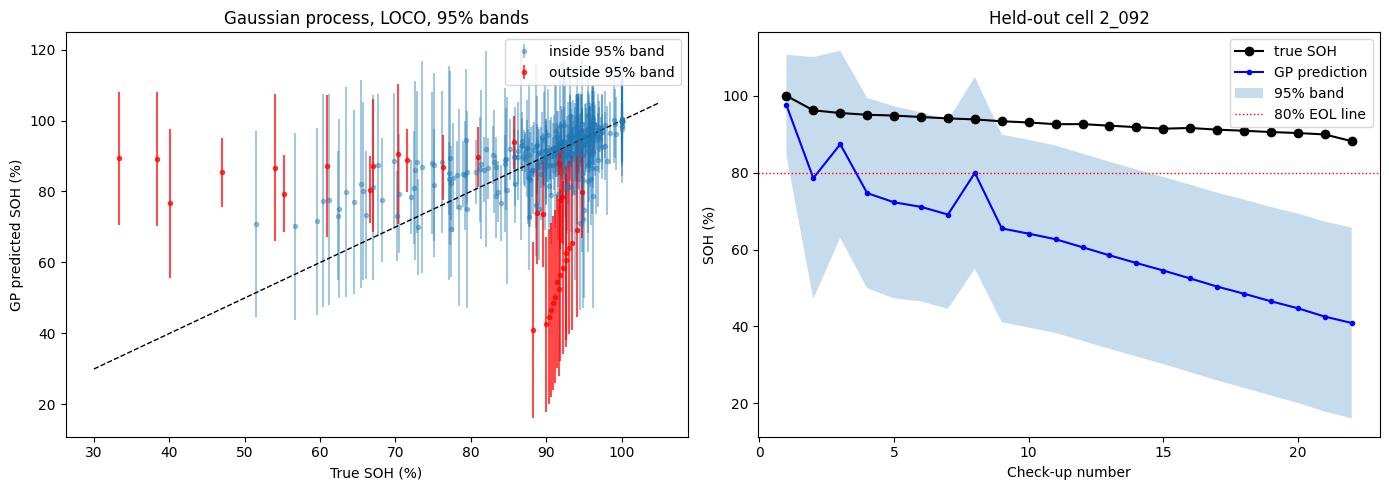

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Left: predicted vs true, with 95% bands
ok = unc.inside_95.to_numpy()
ax[0].errorbar(y[ok], mu[ok], yerr=1.96 * sd[ok], fmt="o", ms=3, alpha=.4, label="inside 95% band")
ax[0].errorbar(y[~ok], mu[~ok], yerr=1.96 * sd[~ok], fmt="o", ms=3, color="red", alpha=.7, label="outside 95% band")
ax[0].plot([30, 105], [30, 105], "k--", lw=1)
ax[0].set(xlabel="True SOH (%)", ylabel="GP predicted SOH (%)", title="Gaussian process, LOCO, 95% bands")
ax[0].legend()

# Right: one held-out cell over time
cell = "2_092"   # try also 2_076, 2_095, 2_009
c = unc[unc.cell_id == cell].sort_values("rtp_index")
ax[1].plot(c.rtp_index, c.y_true, "ko-", label="true SOH")
ax[1].plot(c.rtp_index, c.y_pred, "b.-", label="GP prediction")
ax[1].fill_between(c.rtp_index, c.y_pred - 1.96 * c["std"], c.y_pred + 1.96 * c["std"], alpha=.25, label="95% band")
ax[1].axhline(80, color="red", ls=":", lw=1, label="80% EOL line")
ax[1].set(xlabel="Check-up number", ylabel="SOH (%)", title=f"Held-out cell {cell}")
ax[1].legend()

plt.tight_layout()
plt.savefig("gp_uncertainty.png", dpi=150)
plt.show()

In [8]:
%%time
for scheme in ["LOPO", "Random 5-fold"]:
    for spec in [ridge, svr, gpr]:
        results.append(ev.run_cv(df, spec, scheme))

R = {(r.model, r.scheme): r for r in results}
display(ev.summary_table(results).round(2))
display(ev.generalization_gap(results).round(2))

Ridge | LOPO: fold 14
SVR (RBF) | LOPO: fold 14
Gaussian process | LOPO: fold 14
Ridge | Random 5-fold: fold 5
SVR (RBF) | Random 5-fold: fold 5
Gaussian process | Random 5-fold: fold 5


,model,scheme,n,MAE,RMSE,R2,MaxAE
0,Ridge,LOCO,306,5.02,8.13,0.46,53.21
1,SVR (RBF),LOCO,306,4.58,7.69,0.52,54.76
2,Gaussian process,LOCO,306,7.37,12.38,-0.24,56.06
3,Ridge,LOPO,306,4.59,7.02,0.60,49.88
4,SVR (RBF),LOPO,306,5.04,7.94,0.49,54.65
5,Gaussian process,LOPO,306,8.17,12.91,-0.35,56.06
6,Ridge,Random 5-fold,306,2.79,4.50,0.84,41.24
7,SVR (RBF),Random 5-fold,306,1.24,2.97,0.93,38.41
8,Gaussian process,Random 5-fold,306,1.30,2.88,0.93,35.18


scheme,LOCO,LOPO,Random 5-fold,gap LOCO - random,gap LOPO - random
model,,,,,
Gaussian process,7.37,8.17,1.30,6.07,6.87
Ridge,5.02,4.59,2.79,2.24,1.81
SVR (RBF),4.58,5.04,1.24,3.33,3.80


CPU times: user 1min 20s, sys: 1.84 s, total: 1min 22s
Wall time: 38min 4s


In [9]:
%%time
# 1) Is SVR vs Ridge consistent on LOPO too?
display(pd.DataFrame([
    ev.paired_comparison(R[("SVR (RBF)", "LOPO")],        R[("Ridge", "LOPO")]),
    ev.paired_comparison(R[("Gaussian process", "LOPO")], R[("Ridge", "LOPO")]),
]).round(3))

# 2) Locked hold-out: train on 12 cells, test once on 2_009, 2_092, 2_098
holdout = pd.DataFrame([ev.holdout_check(df, s) for s in [ridge, svr, gpr]])
display(holdout.round(2))

,a,b,scheme,n_folds,mean_diff,a_wins,b_wins,wilcoxon_p
0,SVR (RBF),Ridge,LOPO,14,0.345,7,7,0.391
1,Gaussian process,Ridge,LOPO,14,3.698,3,11,0.025


,model,n_dev_cells,n_test,test_cells,MAE,RMSE
0,Ridge,12,65,"2_009, 2_092, 2_098",4.60,5.82
1,SVR (RBF),12,65,"2_009, 2_092, 2_098",3.24,3.91
2,Gaussian process,12,65,"2_009, 2_092, 2_098",10.62,17.66


CPU times: user 4.96 s, sys: 94.3 ms, total: 5.05 s
Wall time: 1min 47s


In [10]:
import os
out = "results/nonlinear_svr_gpr"
os.makedirs(out, exist_ok=True)

ev.summary_table(results).to_csv(f"{out}/metrics_all_splits.csv", index=False)
ev.generalization_gap(results).to_csv(f"{out}/generalization_gap.csv")
pd.concat([r.folds for r in results]).to_csv(f"{out}/per_fold_metrics.csv", index=False)
pd.concat([r.oof for r in results]).to_csv(f"{out}/oof_predictions.csv", index=False)
pd.DataFrame([ev.paired_comparison(R[(a, s)], R[(b, s)])
              for s in ["LOCO", "LOPO"]
              for a, b in [("SVR (RBF)", "Ridge"), ("Gaussian process", "Ridge"),
                           ("Gaussian process", "SVR (RBF)")]]
            ).to_csv(f"{out}/paired_comparison.csv", index=False)
holdout.to_csv(f"{out}/holdout_check.csv", index=False)
unc.to_csv(f"{out}/gpr_uncertainty_loco.csv", index=False)
os.replace("gp_uncertainty.png", f"{out}/gp_uncertainty.png")

print(sorted(os.listdir(out)))
!zip -qr nonlinear_svr_gpr.zip {out}
from google.colab import files
files.download("nonlinear_svr_gpr.zip")

['generalization_gap.csv', 'gp_uncertainty.png', 'gpr_uncertainty_loco.csv', 'holdout_check.csv', 'metrics_all_splits.csv', 'oof_predictions.csv', 'paired_comparison.csv', 'per_fold_metrics.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>